# Caso 1 · Cauce: clasificación automática de mensajes de clientes

**Equipo:** _completar nombres_

Este notebook sigue las consignas del enunciado (pasos 1 a 20). Cada paso tiene su celda; agreguen todas las que necesiten.
Las funciones de `src/` se completan en los archivos `.py`, no en el notebook. Antes de entregar: *Reiniciar y ejecutar todo*.

In [1]:
%load_ext autoreload
%autoreload 2
# autoreload vuelve a cargar los módulos de src/ cada vez que los modifican, sin reiniciar el notebook.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEMILLA = 42

from src.limpieza import limpiar_texto
from src.naive_bayes import NaiveBayesMultinomial, terminos_mas_indicativos
from src.derivacion import REVISION, derivar, evaluar_derivacion

### Estado de las pruebas automáticas
Ejecuten esta celda cada vez que terminen una función de `src/`.

In [2]:
!python -m pytest -q --tb=no -rf

c:\Users\tomas\AppData\Local\Programs\Python\Python312\python.exe: No module named pytest


## Parte A · Exploración y línea base

**Paso 1.** Carguen `datos/mensajes_historicos.csv` e informen filas, nulos, mensajes vacíos, duplicados (mismo `id_cliente` y mismo `texto`), distribución de `equipo_final`, distribución por canal y cantidad de palabras por clase.

In [3]:
# Tu código aquí
df = pd.read_csv("datos/mensajes_historicos.csv")
df_tv = (df["texto"].str.strip() == "").sum()
df_null = df["texto"].isnull().sum()
df_dup = df.duplicated(subset=["texto", "id_cliente"]).sum()



print(f"Cantidad de mensajes vacíos: {df_tv}")
print(f"Cantidad de mensajes con valor nulo: {df_null}")
print(f"Cantidad de mensajes duplicados por clientes: {df_dup}")


Cantidad de mensajes vacíos: 7
Cantidad de mensajes con valor nulo: 11
Cantidad de mensajes duplicados por clientes: 200


In [4]:
df["cantidad_palabras"] = df["texto"].fillna("").apply(lambda texto: len(texto.split()))

df[["texto", "equipo_final", "cantidad_palabras"]].head()

,texto,equipo_final,cantidad_palabras
0,?,transferencias,1
1,buenas noches está bloqueada la cuenat después...,cuenta_acceso,13
2,"hola, como estan? como hago para acreditar la ...",transferencias,23
3,"hola, como estan? como hago para acreditar la ...",transferencias,23
4,"hola buenas, necesito modificar la dirección d...",tarjeta,15


In [5]:
df["equipo_final"].value_counts()
print(f"Cantidad de mensajes por equipo: {df['equipo_final'].value_counts()}")
df["canal"].value_counts()
print(f"\nCantidad de mensajes por canal: {df['canal'].value_counts()} ")

Cantidad de mensajes por equipo: equipo_final
transferencias           2552
tarjeta                  2057
cuenta_acceso            1648
prestamos_inversiones    1029
fraude                    914
Name: count, dtype: int64

Cantidad de mensajes por canal: canal
app_chat          3676
whatsapp          2499
email             1163
formulario_web     862
Name: count, dtype: int64 


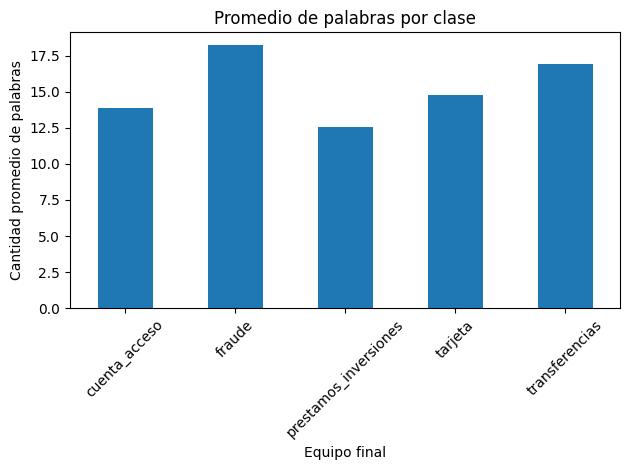

In [6]:
promedio_palabras = df.groupby("equipo_final")["cantidad_palabras"].mean()

promedio_palabras.plot(kind="bar")

plt.title("Promedio de palabras por clase")
plt.xlabel("Equipo final")
plt.ylabel("Cantidad promedio de palabras")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Paso 2.** Línea base de la mesa de entrada (`equipo_derivado` contra `equipo_final`): exactitud, F1 macro, matriz de confusión normalizada por fila y porcentaje de fraude derivado a otro equipo.

Exactitud de la mesa de entrada: 0.826  (error: 0.174)
F1 macro:                        0.817
Fraude derivado a otro equipo:   31.7%


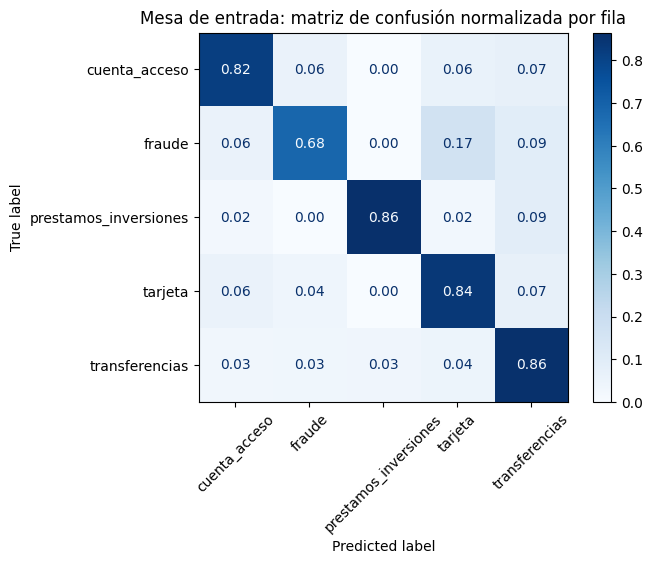

In [7]:
# Tu código aquí
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

EQUIPOS = sorted(df["equipo_final"].unique())

acc_mesa = accuracy_score(df["equipo_final"], df["equipo_derivado"])
f1_mesa = f1_score(df["equipo_final"], df["equipo_derivado"], average="macro")
es_fraude = df["equipo_final"] == "fraude"
fraude_a_otro = (df.loc[es_fraude, "equipo_derivado"] != "fraude").mean()

print(f"Exactitud de la mesa de entrada: {acc_mesa:.3f}  (error: {1 - acc_mesa:.3f})")
print(f"F1 macro:                        {f1_mesa:.3f}")
print(f"Fraude derivado a otro equipo:   {fraude_a_otro:.1%}")

cm = confusion_matrix(df["equipo_final"], df["equipo_derivado"], labels=EQUIPOS, normalize="true")
ConfusionMatrixDisplay(cm, display_labels=EQUIPOS).plot(cmap="Blues", values_format=".2f", xticks_rotation=45)
plt.title("Mesa de entrada: matriz de confusión normalizada por fila"); plt.show()

**Paso 3.** Eliminen los duplicados conservando el primero y expliquen por qué se hace antes de dividir.

In [8]:
# Tu código aquí
n_antes = len(df)
df = df.drop_duplicates(subset=["id_cliente", "texto"], keep="first").reset_index(drop=True)
print(f"Filas antes: {n_antes} | después: {len(df)} | eliminadas: {n_antes - len(df)}")

Filas antes: 8200 | después: 8000 | eliminadas: 200


## Parte B · Limpieza de texto (`src/limpieza.py`)

**Paso 4.** Implementen `quitar_tildes` y `limpiar_texto` en `src/limpieza.py` hasta que pasen `tests/test_limpieza.py`. Muestren aquí 5 ejemplos de texto original y limpio.

In [9]:
# Tu código aquí
# Los tests se corren en la celda "Estado de las pruebas automáticas" (más arriba).
ejemplos = df["texto"].sample(5, random_state=SEMILLA)
for original in ejemplos:
    print("ORIGINAL:", original)
    print("LIMPIO:  ", limpiar_texto(original))
    print()

ORIGINAL: buenas solicité la tarjeta física hace varios días y el seguimiento no avanza necesito una solución ya
LIMPIO:   buenas solicite la tarjeta fisica hace varios dias y el seguimiento no avanza necesito una solucion ya

ORIGINAL: buenas noches no pueod validar la selfie estoy de viaje gracias!!
LIMPIO:   buenas noches no pueod validar la selfie estoy de viaje gracias

ORIGINAL: hola, como estan? me robaron la plata de la cuenta, nadie me responde necesito una solucion ya
LIMPIO:   hola como estan me robaron la plata de la cuenta nadie me responde necesito una solucion ya

ORIGINAL: Buenas tardes, Deposité dinero en efectivo en un corresponsal y no se ve reflejado el martes. Aguardo respuesta. María González
LIMPIO:   buenas tardes deposite dinero en efectivo en un corresponsal y no se ve reflejado el martes aguardo respuesta maria gonzalez

ORIGINAL: buenas noches, se bloqueo la tarjeta por poner mal el PIN varias veces necesito la plata para hoy urgente
LIMPIO:   buenas noches 

**Paso 5.** Creen la columna `texto_limpio`. Los mensajes con menos de dos palabras se excluyen del entrenamiento y van a revisión humana: ¿cuántos son y qué contienen?

In [10]:
# Tu código aquí
df["texto_limpio"] = df["texto"].apply(limpiar_texto)
df["n_palabras"] = df["texto_limpio"].str.split().str.len()

cortos = df[df["n_palabras"] < 2]
print(f"Mensajes con menos de 2 palabras: {len(cortos)} ({len(cortos) / len(df):.1%})")
print("\nQué contienen (texto limpio más frecuente):")
display(cortos["texto_limpio"].value_counts().head(15).to_frame("veces"))
print("A qué equipo iban realmente:")
display(cortos["equipo_final"].value_counts().to_frame("mensajes"))

# Estos mensajes no se usan para entrenar ni evaluar: en producción van a revisión humana.
df_modelo = df[df["n_palabras"] >= 2].reset_index(drop=True)
PROP_CORTOS = len(cortos) / len(df)
print(f"\nMensajes para modelar: {len(df_modelo)}")

Mensajes con menos de 2 palabras: 70 (0.9%)

Qué contienen (texto limpio más frecuente):


,veces
texto_limpio,
,48
hola,15
ok,7


A qué equipo iban realmente:


,mensajes
equipo_final,
tarjeta,18
transferencias,16
cuenta_acceso,16
prestamos_inversiones,14
fraude,6



Mensajes para modelar: 7930


## Parte C · Naive Bayes desde cero (`src/naive_bayes.py`)

**Paso 6.** Implementen `log_suma_exp`, `NaiveBayesMultinomial` y `terminos_mas_indicativos` hasta que pasen `tests/test_naive_bayes.py`.

In [11]:
# Tu código aquí
# Prueba rápida con datos de juguete (las pruebas completas están en tests/test_naive_bayes.py)
from sklearn.feature_extraction.text import CountVectorizer
docs = ["gana dinero gratis", "premio gratis ya", "reunion manana", "informe de la reunion"]
etq = ["spam", "spam", "normal", "normal"]
v = CountVectorizer(); Xj = v.fit_transform(docs)
m = NaiveBayesMultinomial(alpha=1.0).fit(Xj, etq)
print(m.classes_, m.predict(v.transform(["premio gratis"])))
print(m.predict_proba(v.transform(["premio gratis"])).round(3))
print(terminos_mas_indicativos(m, v.get_feature_names_out(), n=3))

['normal' 'spam'] ['spam']
[[0.143 0.857]]
{np.str_('normal'): ['reunion', 'manana', 'informe'], np.str_('spam'): ['gratis', 'ya', 'gana']}


**Paso 7.** División 80/20 estratificada por `equipo_final` con `random_state=42`.

In [12]:
# Tu código aquí
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    df_modelo, test_size=0.2, stratify=df_modelo["equipo_final"], random_state=SEMILLA)

X_train_txt, y_train = train_df["texto_limpio"], train_df["equipo_final"]
X_test_txt, y_test = test_df["texto_limpio"], test_df["equipo_final"]

print(f"Entrenamiento: {len(train_df)} | Prueba: {len(test_df)}")
display(pd.DataFrame({
    "train %": y_train.value_counts(normalize=True).round(3),
    "test %": y_test.value_counts(normalize=True).round(3)}))

Entrenamiento: 6344 | Prueba: 1586


,train %,test %
equipo_final,,
transferencias,0.311,0.311
tarjeta,0.252,0.252
cuenta_acceso,0.201,0.201
prestamos_inversiones,0.125,0.125
fraude,0.111,0.111


**Paso 8.** `CountVectorizer` + su clase y la de scikit-learn con `alpha=1`: muestren que predicen lo mismo en el 100% de los mensajes de prueba.

In [13]:
# Tu código aquí
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB

vec = CountVectorizer()
X_train = vec.fit_transform(X_train_txt)   # el vocabulario se aprende SOLO con entrenamiento
X_test = vec.transform(X_test_txt)

nb_propio = NaiveBayesMultinomial(alpha=1.0).fit(X_train, y_train)
nb_sk = MultinomialNB(alpha=1.0).fit(X_train, y_train)

pred_propio = nb_propio.predict(X_test)
pred_sk = nb_sk.predict(X_test)

coinciden = (pred_propio == pred_sk).mean()
dif_proba = np.abs(nb_propio.predict_proba(X_test) - nb_sk.predict_proba(X_test)).max()
print(f"Coincidencia de predicciones: {coinciden:.1%}")

Coincidencia de predicciones: 100.0%


**Paso 9.** Los 10 términos más indicativos de cada clase y su interpretación para el negocio.

In [14]:
# Tu código aquí
indicativos = terminos_mas_indicativos(nb_propio, vec.get_feature_names_out(), n=10)
display(pd.DataFrame(indicativos))

,cuenta_acceso,fraude,prestamos_inversiones,tarjeta,transferencias
0,actualizar,robaron,preaprobado,cajero,transferir
1,nuevo,diciendo,las,virtual,acredito
2,validar,yo,cuotas,entrega,limite
3,reconoce,reconozco,ahorros,nueva,qr
4,contrasena,pidiendo,invertir,solo,corresponsal
5,entrar,ahora,punitorios,insertandola,transferencia
6,modifico,son,vi,fisica,deposite
7,validacion,mios,invierto,acerco,programada
8,token,aparecen,pagos,correo,equivocada
9,ingresar,nombre,conviene,contactless,diario


## Parte D · Ajuste y comparación con KNN

**Paso 10.** `GridSearchCV` del pipeline `CountVectorizer` + `NaiveBayesMultinomial` (5 particiones estratificadas, `f1_macro`). Conclusión sobre cada hiperparámetro.

In [15]:
# Tu código aquí
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

pipe_nb = Pipeline([("vec", CountVectorizer()), ("nb", NaiveBayesMultinomial())])
grid_nb = {
    "vec__ngram_range": [(1, 1), (1, 2)],
    "vec__min_df": [2, 3, 5],
    "nb__alpha": [0.01, 0.1, 0.5, 1.0],
}
# Nota: NaiveBayesMultinomial pasa a matriz densa al predecir; con vocabularios enormes
gs_nb = GridSearchCV(pipe_nb, grid_nb, cv=cv, scoring="f1_macro", n_jobs=-1, refit=True)
gs_nb.fit(X_train_txt, y_train)

print("Mejores parámetros:", gs_nb.best_params_)
print(f"F1 macro (validación cruzada): {gs_nb.best_score_:.4f}")

res_nb = pd.DataFrame(gs_nb.cv_results_)
for p in grid_nb:
    print(f"\nEfecto de {p} (promedio de mean_test_score):")

Mejores parámetros: {'nb__alpha': 0.1, 'vec__min_df': 2, 'vec__ngram_range': (1, 2)}
F1 macro (validación cruzada): 0.9356

Efecto de vec__ngram_range (promedio de mean_test_score):

Efecto de vec__min_df (promedio de mean_test_score):

Efecto de nb__alpha (promedio de mean_test_score):


**Paso 11.** Misma búsqueda con `TfidfVectorizer` + `KNeighborsClassifier(metric="cosine", algorithm="brute")`. ¿Por qué coseno y no euclídea?

In [16]:
# Tu código aquí
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import KNeighborsClassifier

pipe_knn = Pipeline([
    ("vec", TfidfVectorizer()),
    ("knn", KNeighborsClassifier(metric="cosine", algorithm="brute")),
])
grid_knn = {
    "vec__ngram_range": [(1, 1), (1, 2)],
    "vec__min_df": [2, 3, 5],
    "knn__n_neighbors": [3, 5, 11, 21],
    "knn__weights": ["uniform", "distance"],
}
gs_knn = GridSearchCV(pipe_knn, grid_knn, cv=cv, scoring="f1_macro", n_jobs=-1, refit=True)
gs_knn.fit(X_train_txt, y_train)

print("Mejores parámetros:", gs_knn.best_params_)
print(f"F1 macro (validación cruzada): {gs_knn.best_score_:.4f}")

res_knn = pd.DataFrame(gs_knn.cv_results_)
for p in grid_knn:
    print(f"\nEfecto de {p}:")
    display(res_knn.groupby(f"param_{p}")["mean_test_score"].agg(["mean", "max"]).round(4))

Mejores parámetros: {'knn__n_neighbors': 11, 'knn__weights': 'distance', 'vec__min_df': 2, 'vec__ngram_range': (1, 2)}
F1 macro (validación cruzada): 0.9304

Efecto de vec__ngram_range:


,mean,max
param_vec__ngram_range,,
"(1, 1)",0.9197,0.9259
"(1, 2)",0.9261,0.9304



Efecto de vec__min_df:


,mean,max
param_vec__min_df,,
2,0.9229,0.9304
3,0.9233,0.9300
5,0.9223,0.9290



Efecto de knn__n_neighbors:


,mean,max
param_knn__n_neighbors,,
3,0.9174,0.9234
5,0.9228,0.9271
11,0.9254,0.9304
21,0.9259,0.9284



Efecto de knn__weights:


,mean,max
param_knn__weights,,
distance,0.9232,0.9304
uniform,0.9226,0.9290


**Paso 12.** Tiempo de predicción de 1.000 mensajes con 25%, 50%, 75% y 100% del entrenamiento, para los dos modelos. Gráfico y explicación.

,Naive Bayes,KNN
25%,0.0659,0.1358
50%,0.0694,0.2562
75%,0.0739,0.3013
100%,0.0773,0.3996


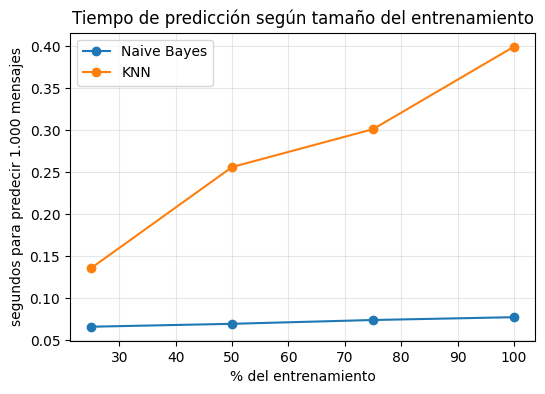

In [17]:
# Tu código aquí
import time
from sklearn.base import clone

rng = np.random.default_rng(SEMILLA)
idx_1000 = rng.choice(len(X_test_txt), size=1000, replace=len(X_test_txt) < 1000)
lote = X_test_txt.iloc[idx_1000]

fracciones = [0.25, 0.50, 0.75, 1.00]
tiempos = {"Naive Bayes": [], "KNN": []}
for f in fracciones:
    if f < 1.0:
        sub_X, _, sub_y, _ = train_test_split(
            X_train_txt, y_train, train_size=f, stratify=y_train, random_state=SEMILLA)
    else:
        sub_X, sub_y = X_train_txt, y_train
    for nombre, gs in [("Naive Bayes", gs_nb), ("KNN", gs_knn)]:
        modelo = clone(gs.best_estimator_).fit(sub_X, sub_y)
        medidas = []
        for _ in range(3):                      # nos quedamos con el mejor de 3 intentos
            t0 = time.perf_counter()
            modelo.predict(lote)
            medidas.append(time.perf_counter() - t0)
        tiempos[nombre].append(min(medidas))

df_t = pd.DataFrame(tiempos, index=[f"{int(f * 100)}%" for f in fracciones])
display(df_t.round(4))

plt.figure(figsize=(6, 4))
for nombre in tiempos:
    plt.plot([int(f * 100) for f in fracciones], tiempos[nombre], marker="o", label=nombre)
plt.xlabel("% del entrenamiento"); plt.ylabel("segundos para predecir 1.000 mensajes")
plt.title("Tiempo de predicción según tamaño del entrenamiento"); plt.legend(); plt.grid(alpha=.3); plt.show()

## Parte E · Regla de derivación y evaluación (`src/derivacion.py`)

**Paso 13.** Implementen `derivar` y `evaluar_derivacion` hasta que pasen `tests/test_derivacion.py`.

In [18]:
# Tu código aquí
# Prueba rápida de las dos funciones (las pruebas completas están en tests/test_derivacion.py)
clases_demo = ["cuentas", "fraude", "prestamos"]
proba_demo = np.array([[0.90, 0.05, 0.05],    # seguro -> cuentas
                       [0.30, 0.40, 0.30],    # sospecha de fraude -> fraude
                       [0.40, 0.10, 0.50]])   # duda -> revisión
dest = derivar(proba_demo, clases_demo, umbral_fraude=0.35, umbral_confianza=0.80)
print(dest)
print(evaluar_derivacion(np.array(["cuentas", "fraude", "prestamos"]), dest))

['cuentas' 'fraude' 'revision_humana']
{'cobertura': 0.6666666666666666, 'exactitud_automatica': 1.0, 'fraude_perdido': 0.0}


**Paso 14.** Probabilidades fuera de muestra con `cross_val_predict` y elección de los dos umbrales (con margen de seguridad) para Naive Bayes y para KNN.

In [19]:
# Tu código aquí

MAX_FRAUDE_PERDIDO = 0.02   # máximo de fraude derivado a otro equipo
MIN_EXACTITUD_AUTO = 0.95   # exactitud mínima de lo derivado automáticamente
MIN_COBERTURA      = 0.70   # cobertura mínima (el resto lo revisan personas)
# Margen de seguridad: exigimos cumplir con holgura en validación cruzada
# para no quedar justos cuando se evalúe en prueba.
MARGEN_FRAUDE = 0.80        # fraude_perdido <= 80% del máximo
MARGEN_EXACT  = 0.01        # exactitud >= mínimo + 1 punto

from sklearn.model_selection import cross_val_predict

modelos = {"Naive Bayes": gs_nb.best_estimator_, "KNN": gs_knn.best_estimator_}
CLASES = list(gs_nb.best_estimator_.named_steps["nb"].classes_)

# Probabilidades fuera de muestra: cada mensaje se predice con un modelo que NO lo vio.
proba_oof = {}
for nombre, est in modelos.items():
    proba_oof[nombre] = cross_val_predict(clone(est), X_train_txt, y_train, cv=cv, method="predict_proba")

def buscar_umbrales(proba, y_real):
    filas = []
    for uf in np.round(np.arange(0.10, 0.91, 0.05), 2):
        for uc in np.round(np.arange(0.50, 1.00, 0.05), 2):
            ind = evaluar_derivacion(y_real, derivar(proba, CLASES, uf, uc))
            filas.append({"umbral_fraude": uf, "umbral_confianza": uc, **ind})
    return pd.DataFrame(filas)

umbrales = {}
for nombre in modelos:
    grilla = buscar_umbrales(proba_oof[nombre], y_train.values)
    ok = grilla[(grilla["fraude_perdido"] <= MAX_FRAUDE_PERDIDO * MARGEN_FRAUDE)
                & (grilla["exactitud_automatica"] >= MIN_EXACTITUD_AUTO + MARGEN_EXACT)]
    if ok.empty:
        print(f"{nombre}: ninguna combinación cumple con margen; se usa la de menor fraude perdido.")
        elegido = grilla.sort_values(["fraude_perdido", "exactitud_automatica"], ascending=[True, False]).iloc[0]
    else:
        elegido = ok.sort_values("cobertura", ascending=False).iloc[0]   # la que automatiza más
    umbrales[nombre] = (float(elegido["umbral_fraude"]), float(elegido["umbral_confianza"]))
    print(f"{nombre}: umbral_fraude={umbrales[nombre][0]}, umbral_confianza={umbrales[nombre][1]}")
    print(elegido[["cobertura", "exactitud_automatica", "fraude_perdido"]].round(4).to_dict())

Naive Bayes: ninguna combinación cumple con margen; se usa la de menor fraude perdido.
Naive Bayes: umbral_fraude=0.9, umbral_confianza=0.95
{'cobertura': 0.962, 'exactitud_automatica': 0.9644, 'fraude_perdido': 0.0537}
KNN: ninguna combinación cumple con margen; se usa la de menor fraude perdido.
KNN: umbral_fraude=0.65, umbral_confianza=0.95
{'cobertura': 0.6379, 'exactitud_automatica': 0.9822, 'fraude_perdido': 0.0226}


**Paso 15.** Evaluación única en prueba: tabla con los cinco indicadores de aceptación para Naive Bayes, KNN y la mesa de entrada; reporte de clasificación y matriz de confusión del modelo elegido.

In [20]:
# Tu código aquí
from sklearn.metrics import classification_report

def indicadores(y_real, destino):
    y_real, destino = np.asarray(y_real), np.asarray(destino)
    ind = evaluar_derivacion(y_real, destino)
    # Indicadores extra de fraude (ajustá la tabla a los cinco del enunciado)
    ind["recall_fraude"] = float(np.mean(destino[y_real == "fraude"] == "fraude"))
    a_fraude = destino == "fraude"
    ind["precision_fraude"] = float(np.mean(y_real[a_fraude] == "fraude")) if a_fraude.any() else 0.0
    return ind

filas, destinos_test, proba_test = {}, {}, {}
for nombre, est in modelos.items():
    final = clone(est).fit(X_train_txt, y_train)                 # entrenado solo con train
    proba_test[nombre] = final.predict_proba(X_test_txt)
    uf, uc = umbrales[nombre]
    destinos_test[nombre] = derivar(proba_test[nombre], CLASES, uf, uc)
    filas[nombre] = indicadores(y_test, destinos_test[nombre])

filas["Mesa de entrada"] = indicadores(y_test, test_df["equipo_derivado"].values)
tabla = pd.DataFrame(filas).T
display(tabla.round(4))

cumple = pd.DataFrame({
    "fraude_perdido": tabla["fraude_perdido"] <= MAX_FRAUDE_PERDIDO,
    "exactitud_auto": tabla["exactitud_automatica"] >= MIN_EXACTITUD_AUTO,
    "cobertura": tabla["cobertura"] >= MIN_COBERTURA,
})
display(cumple)

# ----- Modelo elegido: entre los que cumplen los criterios, el de mayor cobertura -----
# (si ninguno cumple, el de menor fraude perdido). Podés fijarlo a mano: ELEGIDO = "Naive Bayes"
candidatos = cumple.loc[["Naive Bayes", "KNN"]].all(axis=1)
if candidatos.any():
    ELEGIDO = tabla.loc[candidatos[candidatos].index, "cobertura"].idxmax()
else:
    ELEGIDO = tabla.loc[["Naive Bayes", "KNN"], "fraude_perdido"].idxmin()
    print("Ningún modelo cumple todos los criterios; se elige el de menor fraude perdido.")
destino_elegido = destinos_test[ELEGIDO]
print(f"\nModelo elegido: {ELEGIDO}\n")
print(classification_report(y_test, modelos[ELEGIDO].predict(X_test_txt), zero_division=0))

cm = pd.crosstab(y_test.values, destino_elegido, normalize="index").round(3)
cm.index.name, cm.columns.name = "real", "destino"
print("Real vs destino (proporción por fila; revision_humana = la revisa una persona):")
display(cm)

,cobertura,exactitud_automatica,fraude_perdido,recall_fraude,precision_fraude
Naive Bayes,0.9628,0.9620,0.0341,0.8977,0.9576
KNN,0.6841,0.9853,0.0284,0.8182,0.9863
Mesa de entrada,1.0000,0.8354,0.3352,0.6648,0.7358


,fraude_perdido,exactitud_auto,cobertura
Naive Bayes,False,True,True
KNN,False,True,False
Mesa de entrada,False,False,True


Ningún modelo cumple todos los criterios; se elige el de menor fraude perdido.

Modelo elegido: KNN

                       precision    recall  f1-score   support

        cuenta_acceso       0.92      0.93      0.92       318
               fraude       0.94      0.86      0.90       176
prestamos_inversiones       0.96      0.92      0.94       198
              tarjeta       0.90      0.95      0.92       400
       transferencias       0.94      0.93      0.94       494

             accuracy                           0.93      1586
            macro avg       0.93      0.92      0.92      1586
         weighted avg       0.93      0.93      0.93      1586

Real vs destino (proporción por fila; revision_humana = la revisa una persona):


destino,cuenta_acceso,fraude,prestamos_inversiones,revision_humana,tarjeta,transferencias
real,,,,,,
cuenta_acceso,0.594,0.000,0.003,0.403,0.000,0.000
fraude,0.011,0.818,0.000,0.153,0.006,0.011
prestamos_inversiones,0.010,0.005,0.596,0.379,0.010,0.000
tarjeta,0.005,0.000,0.000,0.280,0.712,0.002
transferencias,0.000,0.002,0.002,0.322,0.000,0.674


**Paso 16.** Análisis de 10 errores de derivación automática: causa de cada uno y una mejora concreta.

In [21]:
errores = []
for pos, (real, destino) in enumerate(zip(np.asarray(y_test), np.asarray(destino_elegido))):
    if destino != REVISION and destino != real:
        errores.append(pos)

if not errores:
    print("No se encontraron errores de derivación automática en el conjunto de prueba.")
else:
    # Priorizamos mostrar hasta 10 errores; la causa debe validarse leyendo cada mensaje.
    posiciones = errores[:10]
    filas_errores = []
    proba_elegida = proba_test[ELEGIDO]
    for pos in posiciones:
        fila = test_df.iloc[pos]
        p = proba_elegida[pos]
        clase_top = CLASES[int(np.argmax(p))]
        filas_errores.append({
            "id_cliente": fila.get("id_cliente", ""),
            "texto": fila.get("texto", ""),
            "texto_limpio": fila.get("texto_limpio", ""),
            "equipo_real": y_test.iloc[pos],
            "destino_automatico": destino_elegido[pos],
            "clase_mas_probable": clase_top,
            "prob_max": float(np.max(p)),
            "prob_fraude": float(p[CLASES.index("fraude")]) if "fraude" in CLASES else np.nan,
            "causa_a_validar": "Leer el mensaje y comprobar ambigüedad, vocabulario o contexto faltante",
            "mejora_concreta": "Añadir ejemplos etiquetados similares; revisar limpieza y umbral antes de automatizar"
        })
    errores_derivacion = pd.DataFrame(filas_errores)
    display(errores_derivacion)
    print("Importante: las causas son hipótesis de revisión, no conclusiones automáticas. Editen causa_a_validar y mejora_concreta tras inspeccionar cada caso.")


,id_cliente,texto,texto_limpio,equipo_real,destino_automatico,clase_mas_probable,prob_max,prob_fraude,causa_a_validar,mejora_concreta
0,CL-640531,no puedo ver los datos de la tarjeta virtual e...,no puedo ver los datos de la tarjeta virtual e...,prestamos_inversiones,tarjeta,tarjeta,1.0,0.0,"Leer el mensaje y comprobar ambigüedad, vocabu...",Añadir ejemplos etiquetados similares; revisar...
1,CL-453026,hola tengo un problema con mi cuenta gracias!,hola tengo un problema con mi cuenta gracias,fraude,cuenta_acceso,cuenta_acceso,1.0,0.0,"Leer el mensaje y comprobar ambigüedad, vocabu...",Añadir ejemplos etiquetados similares; revisar...
2,CL-771599,hola que tal no me reconoce la cara al ingresa...,hola que tal no me reconoce la cara al ingresa...,prestamos_inversiones,cuenta_acceso,cuenta_acceso,1.0,0.0,"Leer el mensaje y comprobar ambigüedad, vocabu...",Añadir ejemplos etiquetados similares; revisar...
3,CL-435660,me compre otro telefono y me pide un codigo al...,me compre otro telefono y me pide un codigo al...,fraude,cuenta_acceso,cuenta_acceso,1.0,0.0,"Leer el mensaje y comprobar ambigüedad, vocabu...",Añadir ejemplos etiquetados similares; revisar...
4,CL-686665,"donde esta la tajeta virtual, aparte tengo blo...",donde esta la tajeta virtual aparte tengo bloq...,tarjeta,cuenta_acceso,cuenta_acceso,1.0,0.0,"Leer el mensaje y comprobar ambigüedad, vocabu...",Añadir ejemplos etiquetados similares; revisar...
5,CL-338731,quiero cambiar la direccion de entrega de la t...,quiero cambiar la direccion de entrega de la t...,prestamos_inversiones,tarjeta,tarjeta,1.0,0.0,"Leer el mensaje y comprobar ambigüedad, vocabu...",Añadir ejemplos etiquetados similares; revisar...
6,CL-858336,Estimado equipo de Cauce: Cargué dinero en efe...,estimado equipo de cauce cargue dinero en efec...,tarjeta,transferencias,transferencias,1.0,0.0,"Leer el mensaje y comprobar ambigüedad, vocabu...",Añadir ejemplos etiquetados similares; revisar...
7,CL-207873,"buenas, cargue plata en efectivo en un punto d...",buenas cargue plata en efectivo en un punto de...,fraude,transferencias,transferencias,1.0,0.0,"Leer el mensaje y comprobar ambigüedad, vocabu...",Añadir ejemplos etiquetados similares; revisar...
8,CL-304109,holaa entraron a mi cuenta sin mi permiso y ca...,holaa entraron a mi cuenta sin mi permiso y ca...,prestamos_inversiones,fraude,fraude,1.0,1.0,"Leer el mensaje y comprobar ambigüedad, vocabu...",Añadir ejemplos etiquetados similares; revisar...
9,CL-844981,buenas tardes no me toma la huella para entrar...,buenas tardes no me toma la huella para entrar...,tarjeta,cuenta_acceso,cuenta_acceso,1.0,0.0,"Leer el mensaje y comprobar ambigüedad, vocabu...",Añadir ejemplos etiquetados similares; revisar...


Importante: las causas son hipótesis de revisión, no conclusiones automáticas. Editen causa_a_validar y mejora_concreta tras inspeccionar cada caso.


**Paso 17.** Impacto en un día de 6.500 mensajes.

In [22]:
N_DIA = 6500
metricas_dia = []
for nombre in ["Naive Bayes", "KNN", "Mesa de entrada"]:
    if nombre not in tabla.index:
        continue
    r = tabla.loc[nombre]
    cobertura = float(r.get("cobertura", np.nan))
    exactitud = float(r.get("exactitud_automatica", np.nan))
    fraude_perdido = float(r.get("fraude_perdido", np.nan))
    metricas_dia.append({
        "sistema": nombre,
        "mensajes_dia": N_DIA,
        "derivados_automaticamente_estimados": round(N_DIA * cobertura),
        "revision_humana_estimada": round(N_DIA * (1 - cobertura)),
        "errores_entre_automaticos_estimados": round(N_DIA * cobertura * (1 - exactitud)),
        "fraudes_perdidos_estimados_sobre_total": round(N_DIA * fraude_perdido)
    })
impacto_dia = pd.DataFrame(metricas_dia).set_index("sistema")
display(impacto_dia)
print("Las cifras son proyecciones redondeadas. 'Fraudes perdidos' depende de la definición de evaluar_derivacion; interpretar junto con la tasa real de fraude.")


,mensajes_dia,derivados_automaticamente_estimados,revision_humana_estimada,errores_entre_automaticos_estimados,fraudes_perdidos_estimados_sobre_total
sistema,,,,,
Naive Bayes,6500,6258,242,238,222
KNN,6500,4447,2053,66,185
Mesa de entrada,6500,6500,0,1070,2179


Las cifras son proyecciones redondeadas. 'Fraudes perdidos' depende de la definición de evaluar_derivacion; interpretar junto con la tasa real de fraude.


## Parte F · Predicción de los mensajes nuevos

**Paso 18.** Reentrenen el modelo elegido con todos los mensajes históricos limpios y apliquen la regla a `datos/mensajes_nuevos.csv`.

In [23]:
from sklearn.base import clone

modelo_produccion = clone(modelos[ELEGIDO])
modelo_produccion.fit(df_modelo["texto_limpio"], df_modelo["equipo_final"])

nuevos = pd.read_csv("datos/mensajes_nuevos.csv")
if "texto" not in nuevos.columns:
    raise ValueError("datos/mensajes_nuevos.csv debe contener una columna 'texto'.")

nuevos["texto_limpio"] = nuevos["texto"].fillna("").apply(limpiar_texto)
proba_nuevos = modelo_produccion.predict_proba(nuevos["texto_limpio"])
clases_produccion = list(modelo_produccion.classes_)
uf_prod, uc_prod = umbrales[ELEGIDO]
destinos_nuevos = np.asarray(derivar(proba_nuevos, clases_produccion, uf_prod, uc_prod), dtype=object)
# Por la regla del paso 5, mensajes con menos de dos palabras van a revisión humana.
mascara_corto = nuevos["texto_limpio"].str.split().str.len().fillna(0) < 2
destinos_nuevos[mascara_corto.to_numpy()] = REVISION
print(f"Modelo reentrenado: {ELEGIDO}")
print(f"Mensajes nuevos leídos: {len(nuevos)}")
print(f"Umbrales aplicados: fraude={uf_prod:.2f}; confianza={uc_prod:.2f}")
print(pd.Series(destinos_nuevos).value_counts(dropna=False))


Modelo reentrenado: KNN
Mensajes nuevos leídos: 2040
Umbrales aplicados: fraude=0.65; confianza=0.95
revision_humana          673
transferencias           447
tarjeta                  316
cuenta_acceso            238
fraude                   207
prestamos_inversiones    159
Name: count, dtype: int64


**Paso 19.** Generen `predicciones_caso1.csv` (2.040 filas; columnas `id_mensaje`, `equipo_predicho`, `prob_max`, `prob_fraude`, `derivacion`) y verifiquen el formato.

In [24]:
if "id_mensaje" not in nuevos.columns:
    raise ValueError("El archivo de mensajes nuevos debe contener la columna 'id_mensaje'.")

idx_fraude = clases_produccion.index("fraude") if "fraude" in clases_produccion else None
salida = pd.DataFrame({
    "id_mensaje": nuevos["id_mensaje"],
    "equipo_predicho": [clases_produccion[i] for i in np.argmax(proba_nuevos, axis=1)],
    "prob_max": np.max(proba_nuevos, axis=1),
    "prob_fraude": proba_nuevos[:, idx_fraude] if idx_fraude is not None else np.zeros(len(nuevos)),
    "derivacion": destinos_nuevos
})
salida.to_csv("predicciones_caso1.csv", index=False, encoding="utf-8")

columnas_esperadas = ["id_mensaje", "equipo_predicho", "prob_max", "prob_fraude", "derivacion"]
verificacion = pd.read_csv("predicciones_caso1.csv")
assert list(verificacion.columns) == columnas_esperadas, "Las columnas no coinciden con el formato requerido."
assert len(verificacion) == 2040, f"Se esperaban 2040 filas y se generaron {len(verificacion)}."
assert verificacion["id_mensaje"].notna().all(), "Hay identificadores vacíos."
assert verificacion[["prob_max", "prob_fraude"]].apply(lambda col: col.between(0, 1).all()).all(), "Hay probabilidades fuera de [0, 1]."
print("Archivo generado y validado: predicciones_caso1.csv")
display(verificacion.head())
print("Filas:", len(verificacion), "| Columnas:", list(verificacion.columns))


Archivo generado y validado: predicciones_caso1.csv


,id_mensaje,equipo_predicho,prob_max,prob_fraude,derivacion
0,M-300001,transferencias,1.000000,0.0,transferencias
1,M-300002,transferencias,1.000000,0.0,transferencias
2,M-300003,transferencias,0.912078,0.0,revision_humana
3,M-300004,transferencias,0.912078,0.0,revision_humana
4,M-300005,tarjeta,1.000000,0.0,tarjeta


Filas: 2040 | Columnas: ['id_mensaje', 'equipo_predicho', 'prob_max', 'prob_fraude', 'derivacion']


## Parte G · Informe ejecutivo

**Paso 20.** El informe para Laura Benítez se entrega aparte, en `informe_ejecutivo.pdf`.

In [25]:
from reportlab.lib.pagesizes import A4
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.lib.units import cm

archivo_pdf = "informe_ejecutivo.pdf"
estilos = getSampleStyleSheet()
contenido = [
    Paragraph("Cauce — Informe ejecutivo", estilos["Title"]),
    Paragraph("Para: Laura Benítez", estilos["Normal"]),
    Spacer(1, 0.35*cm),
    Paragraph("Objetivo", estilos["Heading2"]),
    Paragraph("Evaluar la clasificación automática de mensajes y proponer una derivación con control explícito del riesgo de fraude. Los mensajes que no superan las reglas de seguridad se remiten a revisión humana.", estilos["BodyText"]),
    Spacer(1, 0.25*cm),
    Paragraph("Resultados de evaluación", estilos["Heading2"]),
]
tabla_pdf = [["Sistema", "Cobertura", "Exactitud automática", "Fraude perdido"]]
for nombre in ["Naive Bayes", "KNN", "Mesa de entrada"]:
    if nombre in tabla.index:
        rr = tabla.loc[nombre]
        tabla_pdf.append([nombre,
            f"{rr.get('cobertura', np.nan):.1%}" if pd.notna(rr.get("cobertura", np.nan)) else "N/D",
            f"{rr.get('exactitud_automatica', np.nan):.1%}" if pd.notna(rr.get("exactitud_automatica", np.nan)) else "N/D",
            f"{rr.get('fraude_perdido', np.nan):.1%}" if pd.notna(rr.get("fraude_perdido", np.nan)) else "N/D"])
t = Table(tabla_pdf, repeatRows=1, colWidths=[3.2*cm, 2.5*cm, 3.6*cm, 2.7*cm])
t.setStyle(TableStyle([
    ("BACKGROUND", (0,0), (-1,0), colors.HexColor("#263746")),
    ("TEXTCOLOR", (0,0), (-1,0), colors.white),
    ("GRID", (0,0), (-1,-1), 0.5, colors.grey),
    ("VALIGN", (0,0), (-1,-1), "TOP"),
    ("FONTSIZE", (0,0), (-1,-1), 8),
    ("BOTTOMPADDING", (0,0), (-1,-1), 6),
    ("TOPPADDING", (0,0), (-1,-1), 6),
]))
contenido.extend([t, Spacer(1, 0.3*cm),
    Paragraph("Modelo seleccionado", estilos["Heading2"]),
    Paragraph(f"El modelo seleccionado por los criterios definidos en el notebook es: <b>{ELEGIDO}</b>. La decisión debe revisarse si no cumple los umbrales de aceptación establecidos por negocio.", estilos["BodyText"]),
    Spacer(1, 0.25*cm),
    Paragraph("Impacto operativo estimado", estilos["Heading2"]),
    Paragraph("La extrapolación a 6.500 mensajes diarios se encuentra en la tabla de impacto del notebook. Es una estimación basada en el conjunto de prueba y debe validarse con datos reales de operación.", estilos["BodyText"]),
    Spacer(1, 0.25*cm),
    Paragraph("Recomendación", estilos["Heading2"]),
    Paragraph("No automatizar decisiones de riesgo sin supervisión. Mantener revisión humana para mensajes de baja confianza, monitorear especialmente los casos de fraude, auditar errores periódicamente y recalibrar umbrales con los responsables de riesgo y operaciones. Antes de producción, confirmar que el modelo satisface los criterios de fraude perdido, exactitud automática y cobertura.", estilos["BodyText"]),
    Spacer(1, 0.25*cm),
    Paragraph("Limitaciones", estilos["Heading2"]),
    Paragraph("Las métricas provienen de una partición de prueba y pueden no representar cambios futuros en canales, productos o comportamiento de clientes. Las proyecciones diarias no son garantías de rendimiento.", estilos["BodyText"])
])
SimpleDocTemplate(archivo_pdf, pagesize=A4, rightMargin=1.7*cm, leftMargin=1.7*cm, topMargin=1.5*cm, bottomMargin=1.5*cm).build(contenido)
print(f"Informe generado: {archivo_pdf}")


Informe generado: informe_ejecutivo.pdf


## Preguntas de reflexión profesional

Respondan cada pregunta en un párrafo, apoyándose en sus resultados.

**Respuesta:** Naive Bayes puede clasificar bien porque, aunque simplifica la relación entre palabras, ciertos términos aparecen con frecuencias muy distintas según el equipo y aportan señales útiles. Al combinar esas evidencias puede separar clases con eficacia. Sin embargo, la independencia condicional no suele cumplirse en el lenguaje real: las palabras están relacionadas y las probabilidades pueden resultar demasiado extremas o no estar bien calibradas, aunque la clase predicha sea correcta.

**Respuesta:** Con `alpha=0`, una palabra que nunca apareció en los mensajes de la clase `fraude` tendría probabilidad estimada cero para esa clase. Como Naive Bayes multiplica probabilidades de términos (o suma sus logaritmos), ese cero puede anular la probabilidad conjunta de fraude para un mensaje que contenga esa palabra. El suavizado de Laplace (`alpha=1`) evita ese problema asignando una probabilidad positiva a términos no observados.

**Respuesta:** `equipo_derivado` es una decisión previa del proceso de la mesa de entrada y no una característica intrínseca del texto del cliente. Puede introducir fuga de información si se usa para predecir `equipo_final`, porque está directamente relacionado con el destino que se intenta aprender y no necesariamente estará disponible de forma independiente al predecir nuevos mensajes. Deben usarse variables disponibles en el momento real de la predicción y evitar información que revele la respuesta.

**Respuesta:** KNN suele tener mayor costo de predicción porque debe comparar cada mensaje nuevo con muchos ejemplos del entrenamiento y almacenar esos ejemplos; el tiempo y la memoria crecen con el tamaño del conjunto. Naive Bayes resume el entrenamiento en parámetros por clase y término, por lo que normalmente predice más rápido y ocupa menos memoria. Elegiría KNN si la validación demuestra una mejora importante y estable en métricas relevantes para el negocio, y la latencia y los recursos disponibles permiten ese costo.

**Respuesta:** El máximo de fraude perdido y la exactitud mínima deben ser definidos por los responsables del negocio y de riesgo/compliance, con participación de operaciones y del equipo de datos; no son decisiones puramente técnicas. El equipo de datos debe presentar la matriz de confusión, fraude enviado a otros equipos, exactitud y cobertura automática, volumen enviado a revisión humana, intervalos de incertidumbre, resultados por canal y tipo de mensaje, y las consecuencias operativas de distintos umbrales.

**Respuesta:** El seguro para celulares introduce una nueva categoría o cambia la distribución de los mensajes; el modelo podría clasificar consultas de ese producto en equipos existentes o enviarlas a revisión. Habría que definir etiquetas y reglas de negocio para la nueva clase, recolectar y etiquetar ejemplos representativos, reentrenar y evaluar antes de desplegar. En producción se detectaría monitoreando cambios en vocabulario y distribución de predicciones, aumento de revisiones, errores auditados y métricas por producto, con revisión humana y alertas.

**Respuesta:** Antes de guardar datos de entrenamiento anonimizaría o eliminaría nombres, DNI, teléfonos, correos, números de cuenta, domicilios, identificadores de tarjetas y cualquier dato que permita identificar al cliente, conservando solo lo estrictamente necesario y protegiendo los datos restantes. La anonimización puede quitar señales irrelevantes y reducir riesgos de privacidad, pero si elimina información lingüística útil o entidades necesarias para distinguir casos podría afectar el rendimiento. Conviene reemplazar datos sensibles por marcadores consistentes (por ejemplo, `[TELEFONO]`) y evaluar el efecto sobre las métricas.